## Figures 3-11 and Appendix C - Reduced-order model of pleural pressure distribution

In [ ]:
# env: notebook
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import pickle

from collections import Counter, defaultdict
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

import dolfin

from pleural_pressure import MeshDisplacementReader
from candelinc_fe import CP, CandelincFE, ResidualSampling, FiguresCandelincFE

In [ ]:
# %matplotlib widget
%load_ext autoreload
%autoreload 2

In [ ]:
def symm_cmap_and_norm(values):
    # colors = ['#084594', 'white', '#cb181d']
    colors = ["tab:blue", 'white', 'tab:red']
    cmap = LinearSegmentedColormap.from_list("blue_white_red", colors, N=256)

    # Define symmetric normalization (centered at 0)
    vmin, vcenter, vmax = values.min(), 0, values.max()
    vmax_abs = max(abs(vmin), abs(vmax))  # makes color intensity symmetric
    norm = TwoSlopeNorm(vmin=-vmax_abs, vcenter=vcenter, vmax=vmax_abs)

    return cmap, norm

### Download data
The data are available on Zenodo: [10.5281/zenodo.21821594](https://doi.org/10.5281/zenodo.21821594)

In [ ]:
# Download the data from Zenodo, only if they are not already present
zenodo_url = "https://zenodo.org/records/21821594/files"

# Results_ANTE_* and TransportPlansPOT are used to build the reference mesh and to transport the sampled fields
for folder in ["Results_reduced_model", "Results_ANTE_SUP2", "Results_ANTE_PRO1", "TransportPlansPOT"]:
    if not os.path.isdir(folder):
        print(f"Downloading {folder}...")
        !curl -L --fail --retry 5 --retry-all-errors -C - -o {folder}.zip "{zenodo_url}/{folder}.zip?download=1"
        !unzip -oq {folder}.zip && rm -f {folder}.zip
        if not os.path.isdir(folder):
            raise RuntimeError(f"Downloading {folder} failed. Run this cell again: the download resumes where it stopped.")

# Anonymized volunteer information (group, sex, age, BMI)
info_file = "CRF_gb_spiro3d_anonymized.xlsx"
if not os.path.isfile(info_file):
    print(f"Downloading {info_file}...")
    !curl -L --fail --retry 5 --retry-all-errors -o {info_file} "{zenodo_url}/{info_file}?download=1"
    if not os.path.isfile(info_file):
        raise RuntimeError(f"Downloading {info_file} failed. Please run this cell again.")

### Parameters

In [ ]:
pe          = -0.5    # kPa
alpha_lst   = [0.16]
gravity_lst = [1] # [0,1]

rho_solid   = 1e-6
g           = +9.81e3 # mm/s2

### Get pressure data

In [ ]:
region_lst = []
region_lst += ["LL"]
region_lst += ["RL"]

n_phases = 32

In [ ]:
Simulations_name = []
Simulations_name.append("alpha")
Simulations_name.append(alpha_lst)
Simulations_name.append("pe")
Simulations_name.append(pe)

flat_Simulations_name = [item for sublist in Simulations_name for item in (sublist if isinstance(sublist, list) else [sublist])]
Simulations_filename  = '_'.join([str(x) for x in flat_Simulations_name])

# Load the pressure data for the construction of the reduced-order model. It can also be generated in the notebook Fig2c_save_transported_fields.ipynb
# For each simulation, "p" is the estimated pleural pressure and "pf" its fluctuations (p' in the article), i.e. the pleural
# pressure without the prescribed end-exhalation pressure pe and the hydrostatic component.
# "p_transported" and "pf_transported" are the same fields transported to the reference (target) mesh.
with open(f"Results_reduced_model/{Simulations_filename}/results_volunteers.pkl", "rb") as f:
    results_volunteers = pickle.load(f)

In [ ]:
df_info = pd.read_excel("./CRF_gb_spiro3d_anonymized.xlsx", header=[2])
df_info = df_info.iloc[1:, 1:]

In [ ]:
# Concatenate data from both lungs
grouped_data = defaultdict(lambda: defaultdict(list))

for sim in results_volunteers.values():
    acq, vol, reg = sim["acquisition"], sim["ID"], sim["region"]
    pf_vol        = sim["pf_transported"]
    p_vol         = sim["p_transported"]
    volume_vol    = sim["volume_phases"]

    grouped_data[(acq, vol)][f"regions"].append(reg)
    grouped_data[(acq, vol)][f"{reg}_pf"].append(pf_vol)
    grouped_data[(acq, vol)][f"{reg}_p"].append(p_vol)
    grouped_data[(acq, vol)][f"{reg}_volume"].append(volume_vol)

reduced_model = defaultdict(dict)

for (acq, vol), regions_dict in grouped_data.items():
    # Identify which regions are missing for this specific volunteer/position
    missing = [r for r in region_lst if r not in regions_dict["regions"]]
    
    if not missing: # All regions present
        pf_acq_lst = []
        p_acq_lst  = []
        volume_vol_reg = np.zeros((1,n_phases))
        
        
        for reg in region_lst:
            pf_acq_lst.extend(regions_dict[f"{reg}_pf"])
            p_acq_lst.extend(regions_dict[f"{reg}_p"])
            volume_vol_reg += np.array(regions_dict[f"{reg}_volume"])
        
        if acq == "ANTE_PRO1" and vol == "XXXXXX_XXXX24":
            # NOTE The mesh of the LL in volunteer XXXXXX_XXXX24 in ANTE_PRO1 around phases 25, 26 is not correct (in the dynamic mask, some of the right lung, at the base, is defined as left lung). 
            # However, this does not affect the results of the pleural pressure, so we can include them. 
            # To fix this, I manually compute the correct DeltaV_V.
            vol_max  = np.max(volume_vol_reg)
            vol_min  = np.min((volume_vol_reg[0,0], volume_vol_reg[0,-1]))
            DeltaV_V = (vol_max - vol_min) / (volume_vol_reg[0,0])
        else:
            DeltaV_V = (np.max(volume_vol_reg)-np.min(volume_vol_reg))/(volume_vol_reg[0,0])

        if DeltaV_V < 0.5: # In case we want to filter some volunteers with high volume variation
            # If the criteria is DeltaV_V < 0.25, many volunteers with asthma are excluded.
            pf_concatenated = np.concatenate(pf_acq_lst, axis=1)
            p_concatenated  = np.concatenate(p_acq_lst, axis=1)
            pf_norm         = np.linalg.norm(pf_concatenated)

            reduced_model[(acq, vol)]["pf_transported_concatenated"]      = pf_concatenated #/ norm
            reduced_model[(acq, vol)]["pf_transported_concatenated_norm"] = pf_norm
            reduced_model[(acq, vol)]["pf_transported_concatenated_max"]  = np.max(pf_concatenated)
            reduced_model[(acq, vol)]["pf_mean"]  = np.mean(np.mean(pf_concatenated, axis=1))

            # reduced_model[(acq, vol)]["p_end_inh_norm"] = np.mean(np.linalg.norm(pf_concatenated[15:17,:], axis=1))
            reduced_model[(acq, vol)]["pf_end_inh_mean"] = np.mean(np.mean(pf_concatenated[15:17,:], axis=1))
            reduced_model[(acq, vol)]["Delta_p"]         = np.mean(np.mean(p_concatenated[15:17,:], axis=1)) - np.mean(p_concatenated[0,:]) # Delta of total pressure

            reduced_model[(acq, vol)]["volume_exhalation"] = volume_vol_reg[0,0]
            reduced_model[(acq, vol)]["Delta_volume"]      = np.max(volume_vol_reg) - np.min(volume_vol_reg)
            reduced_model[(acq, vol)]["DeltaV_V"]          = DeltaV_V

            if acq in ["ANTE_SUP1", "ANTE_SUP2", "POST_SUP1"]:
                position = "supine"
            elif acq in ["ANTE_PRO1", "ANTE_PRO2", "POST_PRO1"]:
                position = "prone"
            else:
                raise ValueError(f"Unknown position for acquisition {acq}")
            
            reduced_model[(acq, vol)]["position"] = position
            
        else:
            print(f"Skipping volunteer {vol} in {acq} due to high DeltaV_V: {100.*DeltaV_V}%")
            continue
    
    else:
        print (f"Skipping volunteer {vol} in {acq} due to missing regions: {missing}")

n_reduced_model = len(reduced_model)

P_transported = []
for red_mod in reduced_model.values():
    P_transported.append(red_mod["pf_transported_concatenated"])

In [ ]:
count_ante_sup2 = sum(1 for key in reduced_model.keys() if key[0] == "ANTE_SUP2")
count_ante_pro1 = sum(1 for key in reduced_model.keys() if key[0] == "ANTE_PRO1")

print (f"Total number of reduced model entries: {n_reduced_model}")
print(f"Number of 'ANTE_SUP2' elements: {count_ante_sup2}")
print(f"Number of 'ANTE_PRO1' elements: {count_ante_pro1}")

In [ ]:
sup2_ids = {key[1] for key in reduced_model.keys() if key[0] == "ANTE_SUP2"}
pro1_ids = {key[1] for key in reduced_model.keys() if key[0] == "ANTE_PRO1"}

both = sup2_ids.intersection(pro1_ids)
only_sup2 = sup2_ids - pro1_ids
only_pro1 = pro1_ids - sup2_ids

print(f"Present in BOTH: {len(both)}")
print(f"Only in ANTE_SUP2: {len(only_sup2)}")
print(f"Only in ANTE_PRO1: {len(only_pro1)}")

#### Target mesh

In [ ]:
vol_ID_ref      = "XXXXXX_XXXX02"
acquisition_ref = "ANTE_SUP2"

for simulation_i in results_volunteers.values():
    if simulation_i["ID"] == vol_ID_ref and simulation_i["acquisition"] == acquisition_ref:
        alpha_ref   = simulation_i["alpha"]
        gravity_ref = simulation_i["gravity"]
        pe_ref      = simulation_i["pe"]
        break

resultsPath              = f"./Results_{acquisition_ref}/{vol_ID_ref}"
fs_DG0_regions_bmesh_ref = {}

for region in region_lst:
    mesh_unloaded = dolfin.Mesh()
    with dolfin.XDMFFile(f"{resultsPath}/Pleural_pressure_estimation/"
                         f"mesh_unloaded_{region}_alpha{alpha_ref}_gravity{gravity_ref}_pe{pe_ref}.xdmf") as xdmf_in:
        xdmf_in.read(mesh_unloaded)

    bmesh_unloaded = dolfin.BoundaryMesh(mesh_unloaded, "exterior")
    fs_DG0         = dolfin.FunctionSpace(bmesh_unloaded, "DG", 0)
    fs_DG0_regions_bmesh_ref[region] = fs_DG0

### CANDELINC-FE

In [ ]:
os.makedirs(f"Results_reduced_model/{Simulations_filename}/CandelincFE", exist_ok=True)
os.makedirs(f"Results_reduced_model/{Simulations_filename}/CandelincFE/CP_reference", exist_ok=True)
os.makedirs(f"Results_reduced_model/{Simulations_filename}/CandelincFE/Sampling_new_fields", exist_ok=True)

In [ ]:
# Finding outliers based on the interquartile range (IQR) for pf_mean.
# Initially I selected them from 'pf_transported_concatenated_norm' > 200, but that variable does not have physical meaning,
# so I use the IQR method to find the outliers with 'pf_mean' (and I obtain the same ones).
pf_mean_all = []

for (acq, vol_ID), red_mod in reduced_model.items():
    pf_mean_all.append(red_mod["pf_mean"])

q1 = np.percentile(pf_mean_all, 25)
q3 = np.percentile(pf_mean_all, 75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers_lst = []
for (acq, vol_ID), red_mod in reduced_model.items():
    if red_mod["pf_mean"] < lower_bound or red_mod["pf_mean"] > upper_bound:
        outliers_lst.append((acq, vol_ID))
        print(f"Excluding outlier: {vol_ID}, {acq}, pf_mean: {red_mod['pf_mean']:.3f}")

In [ ]:
biomarkers = []
biomarkers += ["ID"]
biomarkers += ["Position"]
biomarkers += ["Groupe"]
biomarkers += ["Sex"]
biomarkers += ["Age"]
# biomarkers += ["Height"]
# biomarkers += ["Weight"]
biomarkers += ["BMI"]
biomarkers += ["pf_transported_concatenated_norm"]
biomarkers += ["pf_transported_concatenated_max"]
biomarkers += ["pf_mean"]
biomarkers += ["volume_exhalation"]
biomarkers += ["Delta_volume"]
biomarkers += ["DeltaV_V"]
biomarkers += ["pf_end_inh_mean"]
biomarkers += ["Delta_p"]

# biomarkers += ["CV", "CI", "CVF", "VEMS", "VEMS/CVF", "VEMS/CV", "DEM", "Texp"]

P_transported_cfe = []
var_dict = defaultdict(list)

for (acq, vol_ID), red_mod in reduced_model.items():
    # Uncomment to restrict certain cases
    vol_state = df_info.loc[df_info['ID_Volunteer'] == vol_ID[-6:], "Groupe"].values[0]
    # if vol_state == "healthy":
    #     continue
    # if vol_state == "asthma":
    #     continue
    # if vol_state == "COPD":
    #     continue

    # if acq == "ANTE_SUP2":
    #     continue
    # if acq == "ANTE_PRO1":
    #     continue

    if vol_ID == "XXXXXX_XXXX05":
        print(f"Excluding: {vol_ID}, to be used later for comparison with the new sampled fields")
        continue

    if (acq, vol_ID) in outliers_lst:
        continue

    P_transported_cfe.append(red_mod["pf_transported_concatenated"])

    for var in biomarkers:
        if var == "ID":
            vol_var = vol_ID

        elif var == "Position":
            vol_pos = acq
            if vol_pos == "ANTE_SUP2":
                vol_var = 0
            elif vol_pos == "ANTE_PRO1":
                vol_var = 1
            else:
                assert 0, f"Unknown position {vol_pos}"

        elif var in ["pf_transported_concatenated_norm",
                     "pf_transported_concatenated_max",
                     "pf_mean",
                     "volume_exhalation",
                     "Delta_volume",
                     "DeltaV_V",
                     "gw_dist",
                     "pf_end_inh_mean",
                     "Delta_p"]:
            vol_var = reduced_model[(acq, vol_ID)][var]

        elif var == "Groupe":
            vol_state = df_info.loc[df_info['ID_Volunteer'] == vol_ID[-6:], var].values[0]
            if vol_state == "healthy":
                vol_var = 0
            elif vol_state == "asthma":
                vol_var = 1
            elif vol_state == "COPD":
                vol_var = 2
            else:
                assert 0, f"Unknown group {vol_state}"

        elif var == "Sex":
            vol_sex = df_info.loc[df_info['ID_Volunteer'] == vol_ID[-6:], var].values[0]
            if vol_sex == "M":
                vol_var = 0
            elif vol_sex == "F":
                vol_var = 1
            else:
                assert 0, f"Unknown sex {vol_sex}"
        else:
            vol_var = df_info.loc[df_info['ID_Volunteer'] == vol_ID[-6:], var].values[0]
        
        var_dict[var].append(vol_var)

P_3d_cfe = np.stack(P_transported_cfe, axis=0)
P_3d_cfe = np.transpose(P_3d_cfe, (2, 1, 0)) # (n_points, n_phases, n_vol)
print(P_3d_cfe.shape)

In [ ]:
print ("Number of subjects in each group (before excluding outliers):")
group_map = df_info.set_index('ID_Volunteer')['Groupe'].to_dict()

unique_volunteers = set(
    key[1][-6:] 
    for key in reduced_model.keys() 
)

volunteer_group_counts = Counter(
    group_map.get(vol_id) 
    for vol_id in unique_volunteers
)

volunteer_group_counts

In [ ]:
# CANDELINC-FE parameters
S, T, A = P_3d_cfe.shape   # spatial pts, time pts, acquisitions
K = 4                      # Number of P1 nodes for the variables

R_lst = np.arange(1, 4)

# Data
X_observed = P_3d_cfe.copy()

# Variables
variables_cfe_combinations = []

# variables_cfe_combinations.append(["Height"])
# variables_cfe_combinations.append(["Height"])
# variables_cfe_combinations.append(["Weight"])
# variables_cfe_combinations.append(["BMI"])
# variables_cfe_combinations.append(["p_transported_concatenated_norm"])
# variables_cfe_combinations.append(["DeltaV_V"])
# variables_cfe_combinations.append(["volume_exhalation"])
# variables_cfe_combinations.append(["Delta_volume"])
# variables_cfe_combinations.append(["DeltaV_V"])
# variables_cfe_combinations.append(["gw_dist-Groupe"])

# Variables for the article
variables_cfe_combinations.append(["Position"])
variables_cfe_combinations.append(["Groupe"])
variables_cfe_combinations.append(["Sex"])

variables_cfe_combinations.append(["Age"])
variables_cfe_combinations.append(["BMI"])
# variables_cfe_combinations.append(["pf_end_inh_mean"])
variables_cfe_combinations.append(["Delta_p"])

variables_cfe_combinations.append(["Age-Position"])
variables_cfe_combinations.append(["BMI-Position"])
# variables_cfe_combinations.append(["pf_end_inh_mean-Position"])
variables_cfe_combinations.append(["Delta_p-Position"])

results_als_combinations = defaultdict(lambda: defaultdict(list))

mse_cp_lst   = [] # Error of the CP decomposition for each R
for R in R_lst:
    print (f"Running Parafac + ALS with rank R={R}")
    # Parafac decomposition for initialization
    normalized_cp, mse_cp = CP().get_normalized_cp_decomposition(data_tensor=P_3d_cfe, rank=R)
    mse_cp_lst.append(mse_cp)

    for variables_cfe_combination in variables_cfe_combinations:
        cfe = CandelincFE(variables_cfe_combination, var_dict, K)
        D, nodes_dict = cfe.build_global_design_matrix()

        mse_als_train_lst = []
        mse_als_test_lst  = []

        # Alternating Least Squares (ALS)
        # U_s_init = np.random.randn(S, R) * 1e-3
        # U_t_init = np.random.randn(T, R) * 5e-3
        U_s_init = normalized_cp["normalized_spatial_cp"] # Shape: (S, R)
        U_t_init = normalized_cp["scaled_temp_cp"]        # Shape: (T, R)
        assert U_s_init.shape[1] == U_t_init.shape[1] == R

        # k-fold cross-validation
        A_indices = np.arange(A)
        np.random.seed(1234)
        np.random.shuffle(A_indices)
        k_folds = 10
        folds   = np.array_split(A_indices, k_folds)

        mse_kfold_train_lst = []
        mse_kfold_test_lst  = []
        for i_folds in range(k_folds):
            test_idx  = folds[i_folds]
            train_idx = np.setdiff1d(A_indices, test_idx)

            X_train = X_observed[:, :, train_idx]
            X_test  = X_observed[:, :, test_idx]

            cfe_matrices, mse_als = cfe.fit(X_train, D[train_idx, :], U_s_init, U_t_init, R, epochs=100)
            mse_kfold_train_lst.append(mse_als)

            U_s, U_t, B = cfe_matrices["U_s"], cfe_matrices["U_t"], cfe_matrices["B"]

            X_pred       = np.einsum('sr,tr,ar->sta', U_s, U_t, D[test_idx, :] @ B)
            mse_als_test = np.mean((X_pred - X_test) ** 2) / np.mean(X_test**2)
            
            mse_kfold_test_lst.append(mse_als_test)

        results_als_combinations[tuple(variables_cfe_combination)]['train_mse'].append(mse_kfold_train_lst) # error in each fold
        results_als_combinations[tuple(variables_cfe_combination)]['test_mse'].append(mse_kfold_test_lst) # error in each fold
    
    print ("\n")

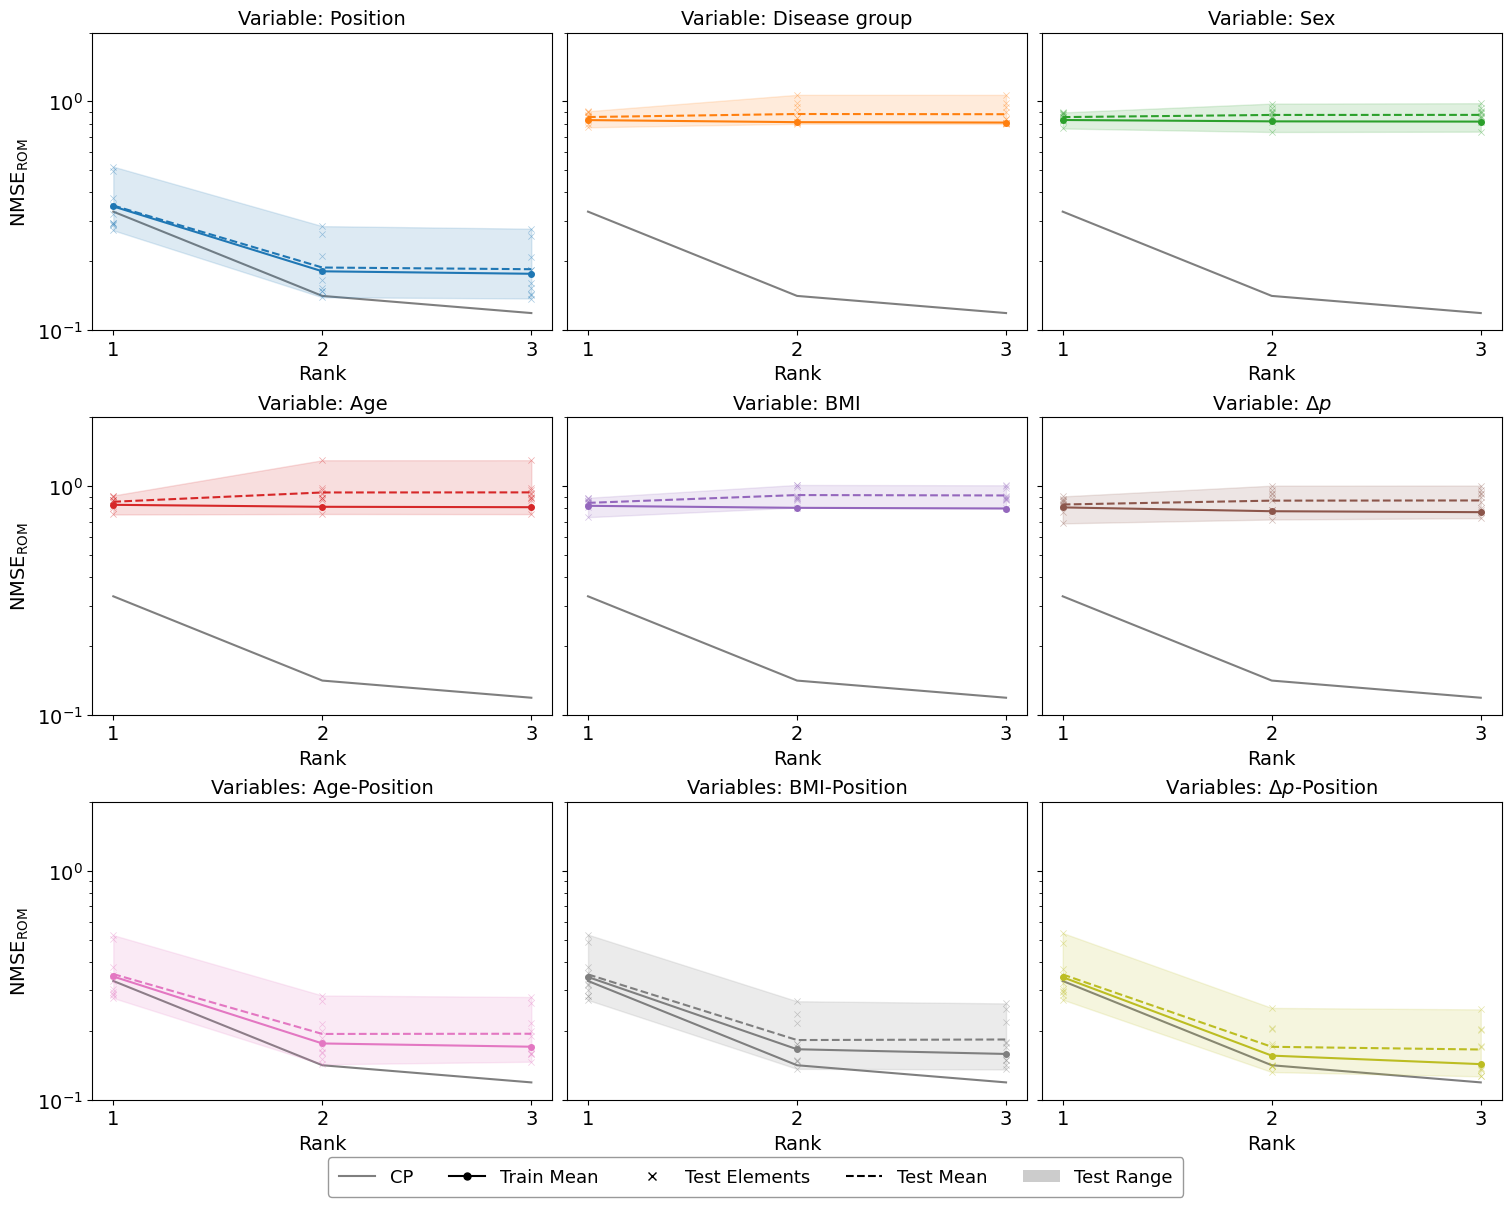

In [ ]:
font_size = 14
n_combinations = len(results_als_combinations)
n_cols_mse = 3
n_rows_mse = (n_combinations + n_cols_mse - 1) // n_cols_mse

# Setup the figure
fig, axes = plt.subplots(
    n_rows_mse, 
    n_cols_mse, 
    figsize=(5 * n_cols_mse, 4 * n_rows_mse), 
    sharey=True, 
    layout='constrained'
)
axs = axes.flatten()
colors = plt.get_cmap('tab10').colors
r_values = np.array(R_lst)

for i, (combo_name, combination_mse) in enumerate(results_als_combinations.items()):
    ax = axs[i]
    color = colors[i % len(colors)]
    label_str = ", ".join(combo_name)
    
    # CP Baseline
    ax.plot(r_values, mse_cp_lst, color='black', linestyle='-', label='CP', alpha=0.5, zorder=1)

    # Train error
    train_means = np.mean(combination_mse['train_mse'], axis=1)
    ax.plot(r_values, train_means, marker='o', markersize=4, color=color, label='Train Mean', zorder=4)

    # Test error
    test_data = np.array(combination_mse['test_mse'])  # Shape: (Ranks, Simulations)
    test_means = np.mean(test_data, axis=1)
    
    # Plot individual test points
    for r_idx, r_val in enumerate(r_values):
        errors = test_data[r_idx, :]
        jitter = np.random.uniform(-0.0, 0.0, size=len(errors))
        ax.scatter(r_val + jitter, errors, marker='x', color=color, s=20, alpha=0.4, linewidths=0.5)

    ax.plot(r_values, test_means, linestyle='--', color=color, label='Test Mean', zorder=5)
    
    ax.fill_between(
        r_values, 
        np.min(test_data, axis=1), 
        np.max(test_data, axis=1), 
        color=color, 
        alpha=0.15, 
        label='Test Range', 
        zorder=2
    )

    # Label replacements
    label_str = label_str.replace("pf_transported_concatenated_norm", r"$p_{\text{norm}}$")
    label_str = label_str.replace("DeltaV_V", r"$\Delta V / V_{\rm{exhal}}$")
    label_str = label_str.replace("pf_end_inh_mean", r"$p_{\rm{i}}$")
    label_str = label_str.replace("Delta_p", r"$\Delta p$")
    label_str = label_str.replace("Groupe", "Disease group")

    if "-" in label_str:
        ax.set_title(f"Variables: {label_str}", size=font_size)
    else:
        ax.set_title(f"Variable: {label_str}", size=font_size)

    ax.set_yscale('log')
    ax.set_xlabel('Rank', size=font_size)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xticks(r_values)
    ax.tick_params(axis="both", labelsize=font_size)
    ax.set_ylim(0.1, 2.)
    
    if i % n_cols_mse == 0:
        ax.set_ylabel(r'$\mathrm{NMSE}_{\mathrm{ROM}}$', size=font_size)

    # # Refined legend to include the 'x' marker indicator
    # test_points_handle = Line2D([0], [0], marker='x', color=color, linestyle='None', label='Test Elements')
    # handles, labels = ax.get_legend_handles_labels()
    # handles.append(test_points_handle)
    # ax.legend(handles=handles, fontsize=font_size-2, loc='upper right')

# Remove unused axes
for j in range(i + 1, len(axs)):
    fig.delaxes(axs[j])

# Single global legend placed outside at the bottom with a styled box
legend_handles = [
    Line2D([0], [0], color='black', linestyle='-', alpha=0.5, label='CP'),
    Line2D([0], [0], marker='o', markersize=5, color='black', label='Train Mean'),
    Line2D([0], [0], marker='x', markersize=6, linestyle='None', color='black', label='Test Elements'),
    Line2D([0], [0], linestyle='--', color='black', label='Test Mean'),
    Patch(facecolor='black', alpha=0.2, edgecolor='none', label='Test Range')
]

fig.legend(
    handles=legend_handles,
    loc='outside lower center',
    ncol=5,
    fontsize=font_size - 1,
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    fancybox=True,
    shadow=False,
    borderpad=0.6
)

plt.savefig(
    f"Results_reduced_model/{Simulations_filename}/CandelincFE/cfe_mse_train_test_filled.pdf", 
    bbox_inches='tight'
)
plt.show()

#### CANDELINC-FE with the selected combination of variables and rank

In [ ]:
R_selected = 2
variables_combo_selected = variables_cfe_combinations[8]
print ("Selected combination for final model:", variables_combo_selected)

cfe = CandelincFE(variables_combo_selected, var_dict, K)
D, nodes_dict = cfe.build_global_design_matrix()

normalized_cp, mse_cp = CP().get_normalized_cp_decomposition(data_tensor=P_3d_cfe, rank=R_selected)

U_s_init = normalized_cp["normalized_spatial_cp"] # (S, R)
U_t_init = normalized_cp["scaled_temp_cp"]        # (T, R)
assert U_s_init.shape[1] == U_t_init.shape[1] == R_selected

cfe_matrices, cfe_mse = cfe.fit(X_observed, D, U_s_init, U_t_init, R_selected, epochs=100)
print (f"Final ALS Loss on full data with R={R_selected}: {cfe_mse:.6f}")

U_s, U_t, B = cfe_matrices["U_s"], cfe_matrices["U_t"], cfe_matrices["B"]

##### Save CP results, as reference

In [ ]:
# Save CP modes
ind_ini = 0
for region in region_lst:
    with dolfin.XDMFFile(f"Results_reduced_model/{Simulations_filename}/CandelincFE/CP_reference/cp_modes_target_{acquisition_ref}_{vol_ID_ref[-2:]}_{region}.xdmf") as xdmf:
        xdmf.parameters["flush_output"] = True
        xdmf.parameters["functions_share_mesh"] = True
        xdmf.parameters["rewrite_function_mesh"] = False
        

        for ind_r in range(R_selected):
            cp_mode_fn = dolfin.Function(fs_DG0_regions_bmesh_ref[region])
            cp_mode_fn.rename(f"cp_{ind_r+1:02d}", f"cp_{ind_r+1:02d}")

            g_r = normalized_cp["scaled_temp_cp"][:, ind_r].reshape(-1,1) @ normalized_cp["normalized_spatial_cp"][ind_ini:ind_ini+fs_DG0_regions_bmesh_ref[region].dim(), ind_r].reshape(1,-1)

            for phase_i in range(n_phases):
                cp_mode_fn.vector()[:] = g_r[phase_i, :]
                xdmf.write(cp_mode_fn, phase_i)
    ind_ini += fs_DG0_regions_bmesh_ref[region].dim()

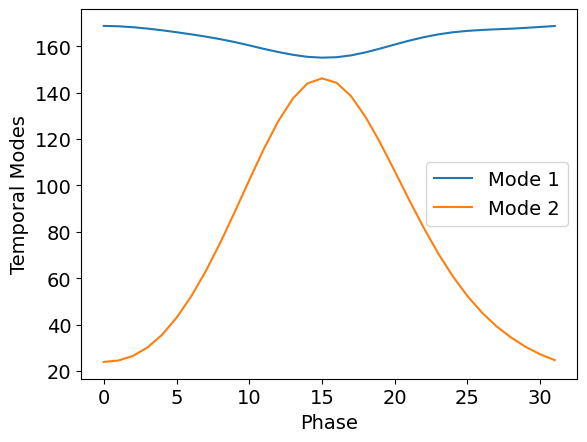

In [ ]:
font_size = 14

# Plot temporal modes
plt.figure()
for ind_r in range(R_selected):
    plt.plot(normalized_cp["scaled_temp_cp"][:, ind_r], label=f'Mode {ind_r+1}')

plt.xlabel('Phase', fontsize=font_size)
plt.ylabel('Temporal Modes', fontsize=font_size)
plt.tick_params(axis='both', labelsize=font_size)
plt.legend(fontsize=font_size)

plt.savefig(f"Results_reduced_model/{Simulations_filename}/CandelincFE/CP_reference/cp_reference_temporal_modes.pdf", bbox_inches='tight')
plt.show()

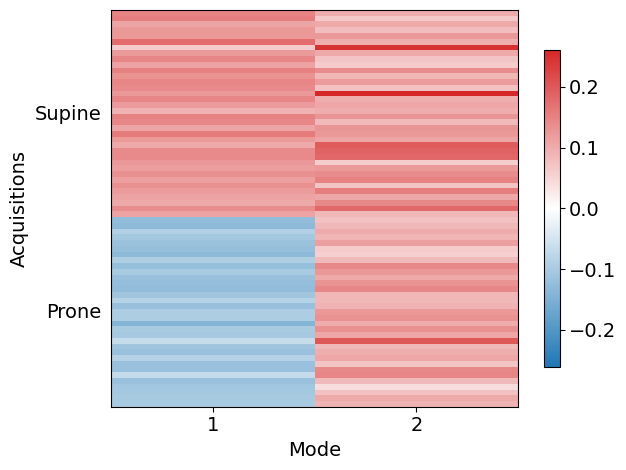

In [ ]:
plt.figure()

cmap, norm = symm_cmap_and_norm(normalized_cp["normalized_acq_cp"])

im = plt.imshow(normalized_cp["normalized_acq_cp"], aspect='auto', cmap=cmap, interpolation='nearest', norm=norm)

# plt.title(rf'CP acq. component')
plt.xlabel('Mode', fontsize=font_size)
plt.ylabel('Acquisitions', fontsize=font_size)

total_acq = normalized_cp["normalized_acq_cp"].shape[0]

pos_supine = total_acq / 4
pos_prone  = 3 * total_acq / 4

plt.yticks([pos_supine, pos_prone], ['Supine', 'Prone'])
plt.xticks(range(R_selected), labels=range(1, R_selected + 1))

plt.tick_params(axis='y', which='both', left=False, labelsize=font_size)
plt.tick_params(axis='x', labelsize=font_size)

cbar = plt.colorbar(im, pad=0.05, shrink=0.8)
cbar.ax.tick_params(labelsize=font_size)

plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
# plt.gca().yaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig(f"Results_reduced_model/{Simulations_filename}/CandelincFE/CP_reference/cp_reference_acq_modes.pdf", bbox_inches='tight')
plt.show()

##### Results of CANDELINC-FE with the selected variables

In [ ]:
# Save CANDELINC-FE modes
ind_ini = 0
for region in region_lst:
    with dolfin.XDMFFile(f"Results_reduced_model/{Simulations_filename}/CandelincFE/cfe_modes_target_{acquisition_ref}_{vol_ID_ref[-2:]}_{region}.xdmf") as xdmf:
        xdmf.parameters["flush_output"] = True
        xdmf.parameters["functions_share_mesh"] = True
        xdmf.parameters["rewrite_function_mesh"] = False
        

        for ind_r in range(R_selected):
            cfe_mode_fn = dolfin.Function(fs_DG0_regions_bmesh_ref[region])
            cfe_mode_fn.rename(f"cfe_{ind_r+1:02d}", f"cfe_{ind_r+1:02d}")

            g_r = U_t[:, ind_r].reshape(-1,1) @ U_s[ind_ini:ind_ini+fs_DG0_regions_bmesh_ref[region].dim(), ind_r].reshape(1,-1)

            for phase_i in range(n_phases):
                cfe_mode_fn.vector()[:] = g_r[phase_i, :]
                xdmf.write(cfe_mode_fn, phase_i)
    ind_ini += fs_DG0_regions_bmesh_ref[region].dim()

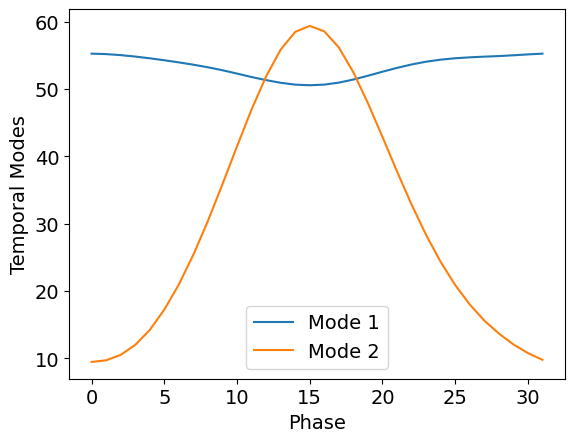

In [ ]:
figures_cfe = FiguresCandelincFE(K, var_dict, U_s, U_t, D, B, variables_combo_selected, nodes_dict)
figures_cfe.plot_temporal_modes(filename=f"Results_reduced_model/{Simulations_filename}/CandelincFE/cfe_temporal_modes.pdf")

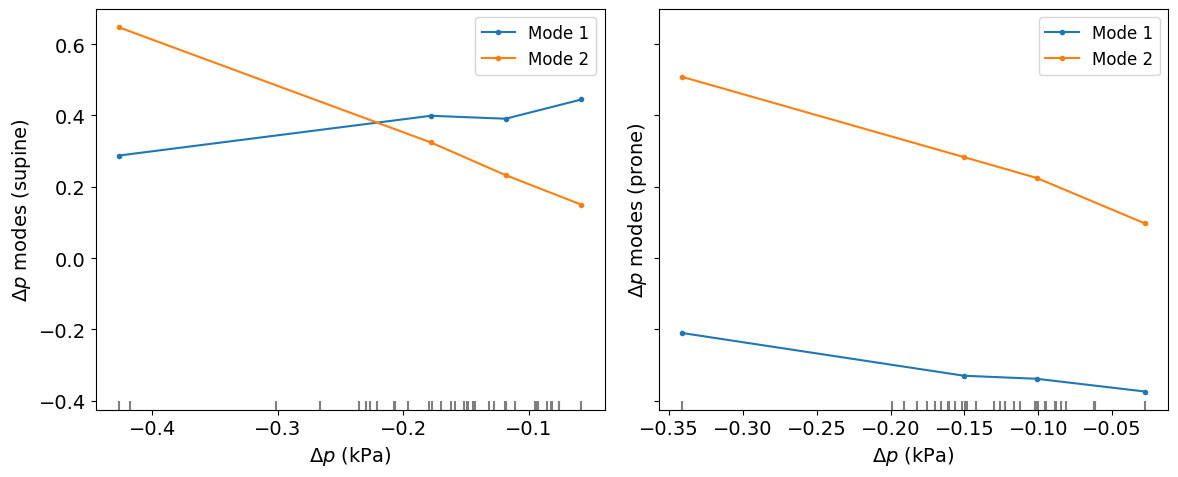

In [ ]:
figures_cfe.plot_variables_modes(filename=f"Results_reduced_model/{Simulations_filename}/CandelincFE/cfe_B_coeffs.pdf")

### CANDELINC-FE - Predicting fields

##### Computing residuals

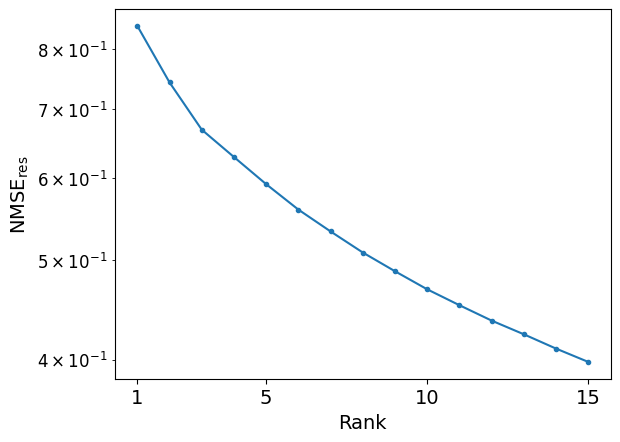

In [ ]:
MSE_r = []
Rr_values = np.linspace(1,15,15).astype(int)
for Rr in Rr_values:
    res_sampling = ResidualSampling(X_observed, U_s, U_t, D, B, variables_combo_selected, nodes_dict, R_residuals=Rr)
    MSE_r.append(res_sampling.Residuals[3])

plt.figure()
plt.plot(Rr_values, MSE_r, '.-')

plt.xlabel('Rank', size=font_size)
plt.ylabel(r'NMSE$_{\text{res}}$', size=font_size)

plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

plt.yscale('log')
plt.xticks(np.array([1,5,10,15]))
plt.tick_params(axis="both", labelsize=font_size)
plt.savefig(f"Results_reduced_model/{Simulations_filename}/CandelincFE/Sampling_new_fields/residual_error_vs_rank.pdf", bbox_inches='tight')
plt.show()

In [ ]:
R_residuals = 3
res_sampling = ResidualSampling(X_observed, U_s, U_t, D, B, variables_combo_selected, nodes_dict, R_residuals=R_residuals)
res_cp_spatial, res_cp_temporal, res_cp_acq, res_cp_mse = res_sampling.Residuals

print ("Residual Sampling Mean and Covariance Matrix:")
print (res_sampling.mvn.mean)
print (res_sampling.mvn.covariance_matrix)

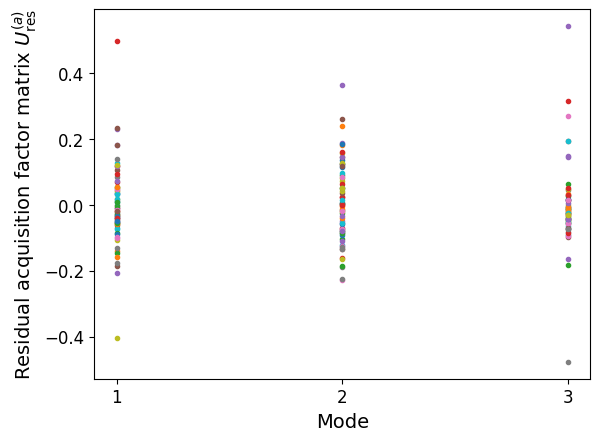

In [ ]:
plt.figure()
for i_vol in range(res_cp_acq.shape[0]): # P_res_acq_cp
    plt.plot(np.arange(1,R_residuals+1),res_cp_acq[i_vol,:], '.', label=f'Acquisition {i_vol+1}') # P_res_acq_cp
plt.xlabel('Mode')
plt.ylabel(r'Residual acquisition factor matrix $U^{(a)}_{\mathrm{res}}$')
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

In [ ]:
# Save CP modes of residual sampling
ind_ini = 0
for region in region_lst:
    with dolfin.XDMFFile(f"Results_reduced_model/{Simulations_filename}/CandelincFE/Sampling_new_fields/residual_modes_{region}.xdmf") as xdmf:
        xdmf.parameters["flush_output"] = True
        xdmf.parameters["functions_share_mesh"] = True
        xdmf.parameters["rewrite_function_mesh"] = False
        

        for Rr in range(R_residuals):
            res_mode_fn = dolfin.Function(fs_DG0_regions_bmesh_ref[region])
            res_mode_fn.rename(f"mode_{Rr+1:02d}", f"mode_{Rr+1:02d}")

            g_r = res_sampling.Residuals[1][:, Rr].reshape(-1,1) @ res_sampling.Residuals[0][ind_ini:ind_ini+fs_DG0_regions_bmesh_ref[region].dim(), Rr].reshape(1,-1)

            for phase_i in range(n_phases):
                res_mode_fn.vector()[:] = g_r[phase_i, :]
                xdmf.write(res_mode_fn, phase_i)
    ind_ini += fs_DG0_regions_bmesh_ref[region].dim()

##### Creating new pleural pressure fields

In [ ]:
ID_comp  = 'XXXXXX_XXXX05'
acq_comp = 'ANTE_SUP2'
# acq_comp = 'ANTE_PRO1'

vars_comp = reduced_model[(acq_comp, ID_comp)]

if acq_comp == "ANTE_SUP2":
    pos_comp = 0
    res_sampling.mvn.rng = np.random.default_rng(123)
elif acq_comp == "ANTE_PRO1":
    pos_comp = 1
    res_sampling.mvn.rng = np.random.default_rng(456)

p_norm_comp    = vars_comp['pf_transported_concatenated_norm']
DV_V_comp      = vars_comp['DeltaV_V']

p_end_inh_comp = vars_comp['pf_end_inh_mean']
Delta_p_comp   = vars_comp['Delta_p']

In [ ]:
mvn_mu  = res_sampling.mvn.mean
mvn_cov = res_sampling.mvn.covariance_matrix

L, V = np.linalg.eigh(mvn_cov)
V = V * -np.sign(V[np.argmax(np.abs(V), axis=0), np.arange(V.shape[1])]) # Sign convention: largest component of each eigenvector is negative
sigma_principal = np.sqrt(L)

c = np.sqrt(stats.chi2.ppf(0.683, df=R_residuals)) # For the 68.3% confidence ellipsoid

offsets = V * sigma_principal 
vertices_plus  = mvn_mu[:, None] + c * offsets
vertices_minus = mvn_mu[:, None] - c * offsets

vertices_ellipsoid = np.stack([vertices_plus, vertices_minus], axis=2).reshape(len(mvn_mu), -1)

In [ ]:
var_dict_new = {
    'Position': [pos_comp],
    'pf_transported_concatenated_norm': [p_norm_comp],
    'DeltaV_V': [DV_V_comp],
    'pf_end_inh_mean': [p_end_inh_comp],
    'Delta_p': [Delta_p_comp] # TODO Select other values
}

D_new     = res_sampling.get_D_new(var_dict_new)

P_f_syn_sampled_lst = []

# Sample from the multivariate normal distribution
# n_sampled = 10
# for i_sampled in range(n_sampled):
#     P_syn   = res_sampling.generate_synthetic_field(D_new)
#     P_f_syn_sampled_lst.append(P_syn) # matrix with n_sampled fields n_samples x n_space x n_phases

# Use values of vertices of the 68.3% confidence ellipsoid 
n_sampled = 2*R_residuals
for i_sampled in range(n_sampled):
    P_syn   = res_sampling.generate_synthetic_field(D_new, coeffs = vertices_ellipsoid[:, i_sampled])
    P_f_syn_sampled_lst.append(P_syn)

P_f_syn = np.stack(P_f_syn_sampled_lst, axis=0) # n_sampled x n_space x n_phases

In [ ]:
# Transport to original geometry
phase_end_exhal = 0
for region in region_lst:
    # Find "inverse" transport plan, to tranport field from reference geometry to the original geometry of the selected volunteer
    for simulation_i in results_volunteers.values():
        if simulation_i['acquisition'] == acq_comp and simulation_i['ID'] == ID_comp and simulation_i['region'] == region:
            alpha_comp   = simulation_i['alpha']
            gravity_comp = simulation_i['gravity']
            pe_comp      = simulation_i['pe']

    with open(f"TransportPlansPOT/{Simulations_filename}/"
            f"target_{acquisition_ref}_{vol_ID_ref[-2:]}_{region}_"
            f"source_{acq_comp}_{ID_comp[-2:]}_{region}.pkl", "rb") as f:
        data        = pickle.load(f)
        T_loaded    = data["T"].toarray()
        log_loaded  = data["log"]
        info_loaded = data["info"]

    if region == "LL":
        ind_ini = 0
    elif region == "RL":
        ind_ini = fs_DG0_regions_bmesh_ref['LL'].dim()

    P_estimation_lst = []
    for i_sampled in range(n_sampled):
        P_syn = P_f_syn[i_sampled, :, :]
        assert fs_DG0_regions_bmesh_ref['LL'].dim() + fs_DG0_regions_bmesh_ref['RL'].dim() == P_syn.shape[0], "Dimension mismatch"


        P_syn_backtransported = np.zeros((T_loaded.shape[0], n_phases))
        for phase_i in range(n_phases):
            P_syn_region            = P_syn[ind_ini:ind_ini+fs_DG0_regions_bmesh_ref[region].dim(), phase_i]
            P_syn_backtransported_i = np.matmul(T_loaded, P_syn_region.reshape(-1,1)) / T_loaded.sum(axis=1, keepdims=True)
            P_syn_backtransported[:,phase_i] = P_syn_backtransported_i.reshape(1,-1)


        # Read end-exhalation mesh
        resultsPath_comp = f"./Results_{acq_comp}/{ID_comp}"
        mesh_unloaded    = dolfin.Mesh()
        with dolfin.XDMFFile(f"{resultsPath_comp}/Pleural_pressure_estimation/"
                            f"mesh_unloaded_{region}_alpha{alpha_comp}_gravity{gravity_comp}_pe{pe_comp}.xdmf") as xdmf_in:
            xdmf_in.read(mesh_unloaded)
        bmesh_unloaded = dolfin.BoundaryMesh(mesh_unloaded, "exterior")
        
        # Read pressure values
        fs_DG0_comp = dolfin.FunctionSpace(bmesh_unloaded, "DG", 0)


        vfs_CG1 = dolfin.VectorFunctionSpace(bmesh_unloaded, "CG", 1)
        U_b   = dolfin.Function(vfs_CG1)

        MDR = MeshDisplacementReader(acq_comp, ID_comp, region, n_phases)

        # Read center of mass
        fs_R           = dolfin.VectorFunctionSpace(bmesh_unloaded, "R", 0)
        center_of_mass = dolfin.Function(fs_R)

        h5_results = dolfin.HDF5File(bmesh_unloaded.mpi_comm(), f"{resultsPath_comp}/Pleural_pressure_estimation/data_{region}_alpha{alpha_comp}_gravity{gravity_comp}_pe{pe_comp}.h5", "r")


        p_estimation = np.zeros((bmesh_unloaded.num_cells(), n_phases))

        for phase_i in range(n_phases):
            U_b_name = "/U_b/vector_%d"%phase_i
            h5_results.read(U_b, U_b_name)
            bmesh_deformed_phase_i = dolfin.BoundaryMesh(mesh_unloaded, "exterior")
            dolfin.ALE.move(bmesh_deformed_phase_i, U_b)
            
            fs_DG0_phase_i         = dolfin.FunctionSpace(bmesh_deformed_phase_i, "DG", 0)
            def_cells_coords       = fs_DG0_phase_i.tabulate_dof_coordinates()

            cent_name = "/center_of_mass/vector_%d"%phase_i
            h5_results.read(center_of_mass, cent_name)
            

            x_tilde       = def_cells_coords - center_of_mass.vector().get_local().reshape(1,-1)
            p_syn_phase_i = pe_comp + rho_solid * x_tilde.dot(np.array([gravity_comp*g, 0, 0])) + P_syn_backtransported[:, phase_i]
            p_estimation[:, phase_i] = p_syn_phase_i

        P_estimation_lst.append(p_estimation)

        
    ## Save P in original geometry
    p_est_fn = dolfin.Function(fs_DG0_comp)
    with dolfin.XDMFFile(f"Results_reduced_model/{Simulations_filename}/CandelincFE/Sampling_new_fields/Sampled_P_{ID_comp[-2:]}_{acq_comp}_{region}.xdmf") as xdmf:
        xdmf.parameters["flush_output"] = True
        xdmf.parameters["functions_share_mesh"] = True
        xdmf.parameters["rewrite_function_mesh"] = False

        for i_sampled in range(n_sampled):
            p_est_fn.rename(f"p_syn{i_sampled}", f"p_syn{i_sampled}")
            for phase_i in range(n_phases):
                p_est_fn.vector()[:] = P_estimation_lst[i_sampled][:, phase_i].ravel()
                xdmf.write(p_est_fn, phase_i)
        

##### Error vs original field

In [ ]:
for n_sim, simulation_i in results_volunteers.items():
    
    if simulation_i["ID"] == vol_ID_ref and simulation_i["acquisition"] == acquisition_ref:
        p_org_ref = simulation_i["p"]

        if simulation_i["region"] == "LL":
            P_ref_LL = p_org_ref

        elif simulation_i["region"] == "RL":
            P_ref_RL = p_org_ref

P_ref_list = []
for region in region_lst:
    P_ref_list.append(P_ref_LL if region == "LL" else P_ref_RL)

P_ref = np.concatenate(P_ref_list, axis=1)

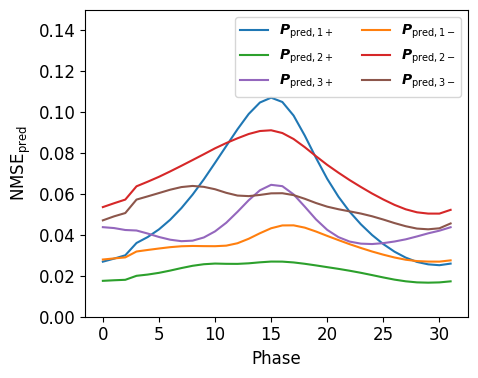

In [ ]:
font_size = 12
n_rows_err_sampled = 1
n_cols_err_sampled = 1

fig, axes = plt.subplots(n_rows_err_sampled, n_cols_err_sampled, figsize=(5 * n_cols_err_sampled, 4 * n_rows_err_sampled), sharey=True)
# axes = axes.flatten()

P_f_reference = reduced_model[acq_comp, ID_comp]['pf_transported_concatenated']

for i_sampled in range(n_sampled):
    P_f_i = P_f_syn[i_sampled,:,:].T

    err_phases = np.zeros(n_phases)
    for phase_i in range(n_phases):
        err_phases[phase_i] = np.linalg.norm((P_f_reference[phase_i,:] - P_f_i[phase_i,:]))**2 / np.linalg.norm(P_ref[phase_i,:])**2

    axes.plot(err_phases) 

axes.set_xlabel('Phase', fontsize=font_size)
axes.set_ylabel(r"$\mathrm{NMSE}_{\mathrm{pred}}$", fontsize=font_size)
axes.tick_params(axis="both", labelsize=font_size)

# axes.set_xlim([0,31])
axes.set_ylim([0,0.15])

labels = []
for i in range(1, R_residuals + 1):
    labels.append(rf"$\boldsymbol{{P}}_{{\mathrm{{pred}}, {i}+}}$")
    labels.append(rf"$\boldsymbol{{P}}_{{\mathrm{{pred}}, {i}-}}$")

labels_col_order = labels[0::2] + labels[1::2]

handles = axes.lines
handles_col_order = handles[0::2] + handles[1::2]

axes.legend(handles_col_order, labels_col_order, fontsize=font_size - 2, loc="upper right", ncols=2, frameon=True)

# axes.set_yticks(np.arange(12, 32, 3))

plt.tight_layout()
plt.savefig(f"Results_reduced_model/{Simulations_filename}/CandelincFE/Sampling_new_fields/error_sampled_fields_{acq_comp}.pdf", bbox_inches='tight')
plt.show()